# Exploration de la source OpenSky Network

## 1. Contexte et objectif du notebook

Je commence l'exploration des données par OpenSky Network (`https://opensky-network.org/api/states/all`), la première des trois sources du projet, après avoir lu la documentation de l'API (`https://openskynetwork.github.io/opensky-api/`).

L'idée est simple : avant de développer les modules d'ingestion pour OpenWeather et NewsAPI, je veux comprendre ce que me donne vraiment cette première source.

OpenSky fournit la variable cible potentielle (le retard, calculé à partir d'un écart horaire) et plusieurs features opérationnelles (position, altitude, vitesse, avion).
L'exploration des données permettra de vérifier la complétude, la fraîcheur, les valeurs aberrantes... avant de construire un schéma en étoile en Phase 2.

Point important : l'API `/states/all` renvoie un instantané de la position de tous les avions suivis au moment de la requête, pas un historique.
Si je relance ce notebook demain, les chiffres seront différents. Les résultats commentés ci-dessous correspondent à une capture précise, dont l'horodatage est affiché juste après.


In [1]:
import glob
import json
import os
import sys
import warnings
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import pandas as pd

# On se place à la racine du projet pour retrouver src/, config/ et le fichier .env
RACINE_PROJET = os.path.abspath(os.path.join(os.getcwd(), ".."))
if RACINE_PROJET not in sys.path:
    sys.path.insert(0, RACINE_PROJET)
os.chdir(RACINE_PROJET)

from src.ingestion.opensky_client import OpenSkyClient
from src.utils.chemins import chemin_relatif_projet

pd.set_option("display.max_columns", None)


## 2. Récupération et chargement des données

J'interroge l'API sur une "bounding box" (bbox) couvrant l'Europe au sens large (latitude 34° à 71°, longitude -25° à 45°), plutôt qu'une zone limitée à la France. Avec une bbox restreinte à la France, je n'aurais récupéré qu'une poignée d'avions à un instant donné — pas assez pour une exploration statistique concluante (distributions, complétude, valeurs aberrantes). L'Europe entière doit donner un trafic dense et varié, plus proche de ce que verra le pipeline en production.

J'appelle l'API OpenSky en direct via `OpenSkyClient`, puis je sauvegarde le résultat dans `data/raw/` (fichier JSON horodaté, non versionné). Si l'appel réseau échoue, le notebook retombe automatiquement sur le fichier le plus récent déjà présent dans `data/raw/`, pour que le reste du notebook reste exécutable même hors connexion.

In [2]:
# Bounding box couvrant l'Europe au sens large : (la min, lo min, la max, lo max)
BBOX_EUROPE = (34.0, -25.0, 71.0, 45.0)
DOSSIER_DONNEES_BRUTES = os.path.join(RACINE_PROJET, "data", "raw")

try:
    client = OpenSkyClient()
    donnees_brutes = client.recuperer_vols_en_temps_reel(bbox=BBOX_EUROPE)
    chemin_fichier = client.sauvegarder_donnees_brutes(
        donnees_brutes, dossier=DOSSIER_DONNEES_BRUTES
    )
    print(f"Nouvel appel API réussi, données sauvegardées dans : {chemin_relatif_projet(chemin_fichier)}")
except Exception as erreur:
    print(f"Appel API impossible ({erreur}), réutilisation du dernier fichier disponible dans data/raw/.")
    fichiers_existants = sorted(glob.glob(os.path.join(DOSSIER_DONNEES_BRUTES, "opensky_*.json")))
    if not fichiers_existants:
        raise
    chemin_fichier = fichiers_existants[-1]
    with open(chemin_fichier, encoding="utf-8") as fichier:
        donnees_brutes = json.load(fichier)

# "time" est un timestamp Unix : l'instant de l'instantané côté OpenSky, pas
# l'instant de réception côté module d'ingestion
horodatage_capture = datetime.fromtimestamp(donnees_brutes["time"], tz=timezone.utc)
print(f"Fichier utilisé : {chemin_relatif_projet(chemin_fichier)}")
print(f"Horodatage de la capture (UTC) : {horodatage_capture}")
print(f"Taille du fichier : {os.path.getsize(chemin_fichier) / 1024:.1f} Ko")


2026-08-25 16:38:46,430 - src.ingestion.opensky_client - INFO - Appel à l'API OpenSky Network réussi (code 200).
2026-08-25 16:38:46,586 - src.ingestion.opensky_client - INFO - Données brutes sauvegardées dans 'data/raw/opensky_20260825_163846.json'.


Nouvel appel API réussi, données sauvegardées dans : data/raw/opensky_20260825_163846.json
Fichier utilisé : data/raw/opensky_20260825_163846.json
Horodatage de la capture (UTC) : 2026-08-25 14:38:28+00:00
Taille du fichier : 1139.8 Ko


In [3]:
# L'API renvoie les états sous forme de listes positionnelles, dans l'ordre
# documenté par la spécification officielle de l'endpoint /states/all
NOMS_COLONNES_ETATS = [
    "icao24",
    "callsign",
    "origin_country",
    "time_position",
    "last_contact",
    "longitude",
    "latitude",
    "baro_altitude",
    "on_ground",
    "velocity",
    "true_track",
    "vertical_rate",
    "sensors",
    "geo_altitude",
    "squawk",
    "spi",
    "position_source",
]

df_vols = pd.DataFrame(donnees_brutes["states"], columns=NOMS_COLONNES_ETATS)

print(f"Nombre de lignes (avions observés) : {df_vols.shape[0]}")
print(f"Nombre de colonnes : {df_vols.shape[1]}")
df_vols.info()


Nombre de lignes (avions observés) : 4210
Nombre de colonnes : 17
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4210 entries, 0 to 4209
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   icao24           4210 non-null   object 
 1   callsign         4210 non-null   object 
 2   origin_country   4210 non-null   object 
 3   time_position    4210 non-null   int64  
 4   last_contact     4210 non-null   int64  
 5   longitude        4210 non-null   float64
 6   latitude         4210 non-null   float64
 7   baro_altitude    3854 non-null   float64
 8   on_ground        4210 non-null   bool   
 9   velocity         4209 non-null   float64
 10  true_track       4210 non-null   float64
 11  vertical_rate    3831 non-null   float64
 12  sensors          0 non-null      object 
 13  geo_altitude     3772 non-null   float64
 14  squawk           3510 non-null   object 
 15  spi              4210 non-null   bool   

## 3. Combien de vols récupère-t-on en un seul appel ? Quelle est la fraîcheur des données ?

Le champ `time_position` indique quand la position d'un avion a été mesurée par les récepteurs ADS-B — un instant qui peut être légèrement antérieur à celui de la requête (`time`, au niveau global de la réponse). Je calcule l'écart entre les deux pour voir à quel point les positions reçues sont vraiment fraîches.


In [4]:
df_vols["age_position_secondes"] = donnees_brutes["time"] - df_vols["time_position"]

print(f"Nombre d'avions récupérés en un seul appel : {len(df_vols)}")
print()
print("Distribution de l'âge des positions (en secondes) :")
print(df_vols["age_position_secondes"].describe())
print()
seuil_secondes = 300
nb_positions_anciennes = (df_vols["age_position_secondes"] > seuil_secondes).sum()
part_positions_anciennes = nb_positions_anciennes / len(df_vols) * 100
print(
    f"Positions vieilles de plus de {seuil_secondes} s (5 min) : "
    f"{nb_positions_anciennes} ({part_positions_anciennes:.1f} % du total)"
)


Nombre d'avions récupérés en un seul appel : 4210

Distribution de l'âge des positions (en secondes) :
count     4210.000000
mean        49.150356
std        409.898765
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max      14897.000000
Name: age_position_secondes, dtype: float64

Positions vieilles de plus de 300 s (5 min) : 91 (2.2 % du total)


**Observations** : un seul appel a renvoyé 4 210 avions sur la zone européenne choisie. La moitié des positions ont un écart quasi nul (quasiment du temps réel), mais la moyenne (environ 49 s) est beaucoup plus haute que la médiane, tirée vers le haut par une minorité de positions bien plus anciennes (jusqu'à 14 897 s, soit plus de 4h). Ce sont probablement des avions sortis de la couverture des récepteurs ADS-B alors qu'ils étaient encore suivis — l'API continue d'afficher leur dernière position connue.

Environ 2,2 % des positions (91 sur 4 210) dépassent les 5 minutes : une proportion faible, mais qu'il faudra filtrer explicitement en Phase 2, une position vieille de plusieurs heures ne devant pas être traitée comme une observation temps réel. (Comme rappelé en introduction, ces chiffres varient à chaque nouvelle exécution du notebook puisque l'API renvoie un instantané en direct.)

## 4. Quels champs sont systématiquement vides ou nuls, et dans quelle proportion ?

Je calcule le taux de complétude de chaque colonne (proportion de valeurs non nulles), puis je l'affiche pour repérer tout de suite les colonnes qui posent problème.


sensors                    0.00
squawk                    83.37
geo_altitude              89.60
vertical_rate             91.00
baro_altitude             91.54
velocity                  99.98
icao24                   100.00
spi                      100.00
true_track               100.00
on_ground                100.00
latitude                 100.00
longitude                100.00
last_contact             100.00
time_position            100.00
origin_country           100.00
callsign                 100.00
position_source          100.00
age_position_secondes    100.00
dtype: float64


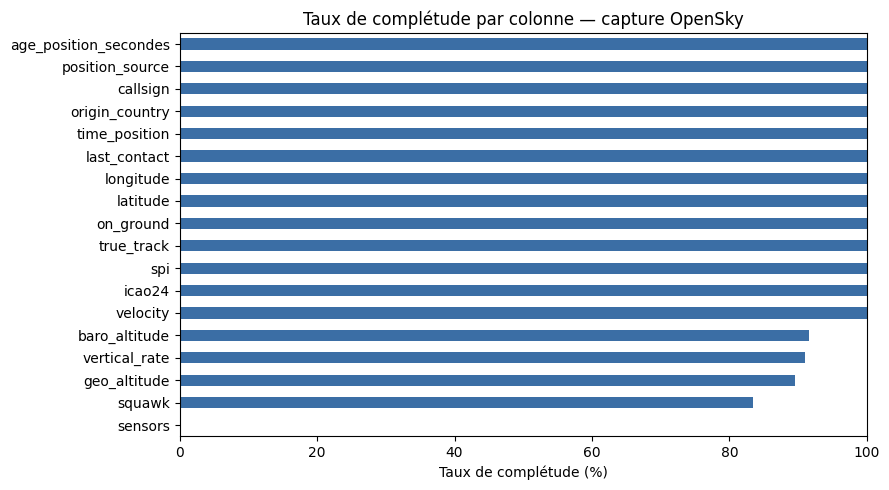

In [5]:
taux_completude = (df_vols.notna().mean() * 100).sort_values()
print(taux_completude.round(2))

fig, ax = plt.subplots(figsize=(9, 5))
taux_completude.plot(kind="barh", ax=ax, color="#3b6ea5")
ax.set_xlabel("Taux de complétude (%)")
ax.set_title("Taux de complétude par colonne — capture OpenSky")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()


**Observations** : la colonne `sensors` est vide à 100 % — ce champ n'est documenté par OpenSky que pour des requêtes authentifiées avec filtrage par capteur, ce qui n'est pas notre cas (requête par bounding box) ; elle est inexploitable et pourra disparaître dès le nettoyage. `squawk` (code transpondeur) manque pour environ 17 % des avions, `geo_altitude` pour environ 10 %, `baro_altitude` pour environ 8 % et `vertical_rate` pour environ 9 %.

### Est-ce que les baro_altitude manquants sont surtout des avions au sol ?

In [6]:
taux_manquant_baro_par_statut = df_vols.groupby("on_ground")["baro_altitude"].apply(
    lambda colonne: colonne.isna().mean() * 100
)
print("Taux de baro_altitude manquant selon le statut au sol (on_ground) :")
print(taux_manquant_baro_par_statut.round(2))


Taux de baro_altitude manquant selon le statut au sol (on_ground) :
on_ground
False     0.03
True     94.67
Name: baro_altitude, dtype: float64


**Observations** : En croisant avec `on_ground`, l'hypothèse se confirme :
Quand l'avion est au sol, `baro_altitude` manque dans plus de 94 % des cas (logique, l'altitude en vol n'a pas de sens au sol), contre moins de 0,1 % pour les avions en vol.
Ce n'est donc pas un problème de qualité de la source, mais un comportement à gérer via une logique conditionnelle (distinguer sol/vol).

Le taux de complétude ci-dessus repose sur les valeurs nulles au sens de pandas. Deux angles morts restent à couvrir avant de faire confiance à ces pourcentages : les doublons, puisque `icao24` (l'adresse unique du transpondeur) est l'identifiant naturel de cette table et ne devrait jamais apparaître deux fois dans un même instantané, et les chaînes vides ou réduites à des espaces, qui passent pour renseignées alors qu'elles ne portent aucune information.

In [7]:
nb_icao24_distincts = df_vols["icao24"].nunique()
nb_doublons_icao24 = len(df_vols) - nb_icao24_distincts

print(f"Lignes : {len(df_vols)}")
print(f"Adresses icao24 distinctes : {nb_icao24_distincts}")
print(f"Doublons sur icao24 : {nb_doublons_icao24}")
print()

# Une chaîne vide ou faite d'espaces reste vue comme renseignée par notna()
for colonne in ("icao24", "callsign", "origin_country", "squawk"):
    valeurs = df_vols[colonne].dropna()
    nb_vides = valeurs.str.strip().eq("").sum()
    print(
        f"{colonne} : {nb_vides} valeur(s) vide(s) ou faite(s) uniquement d'espaces "
        f"sur {len(valeurs)} valeur(s) non nulle(s)"
    )

Lignes : 4210
Adresses icao24 distinctes : 4210
Doublons sur icao24 : 0

icao24 : 0 valeur(s) vide(s) ou faite(s) uniquement d'espaces sur 4210 valeur(s) non nulle(s)
callsign : 43 valeur(s) vide(s) ou faite(s) uniquement d'espaces sur 4210 valeur(s) non nulle(s)
origin_country : 0 valeur(s) vide(s) ou faite(s) uniquement d'espaces sur 4210 valeur(s) non nulle(s)
squawk : 0 valeur(s) vide(s) ou faite(s) uniquement d'espaces sur 3510 valeur(s) non nulle(s)


**Observations** : aucun doublon sur `icao24`, les 4210 lignes correspondent bien à 4210 avions distincts — cet appel renvoie donc un instantané propre, sans réémission de la même position.

Le contrôle des chaînes vides nuance en revanche le taux de complétude calculé juste avant :
`callsign` était annoncé complet à 100 %, alors que 43 de ses valeurs sont en réalité des suites d'espaces, soit une complétude réelle d'environ 99 %.

Il faudra donc convertir ces chaînes vides en valeurs manquantes dès le chargement, sinon l'indicatif de vol paraîtra toujours renseigné.

Les trois autres colonnes textuelles (`icao24`, `origin_country`, `squawk`) ne présentent aucune valeur vide déguisée.

## 5. Quelle est la distribution géographique des positions récupérées ?

Je visualise les positions sous forme de nuage de points latitude/longitude — un simple scatter plot suffit à voir la répartition géographique.


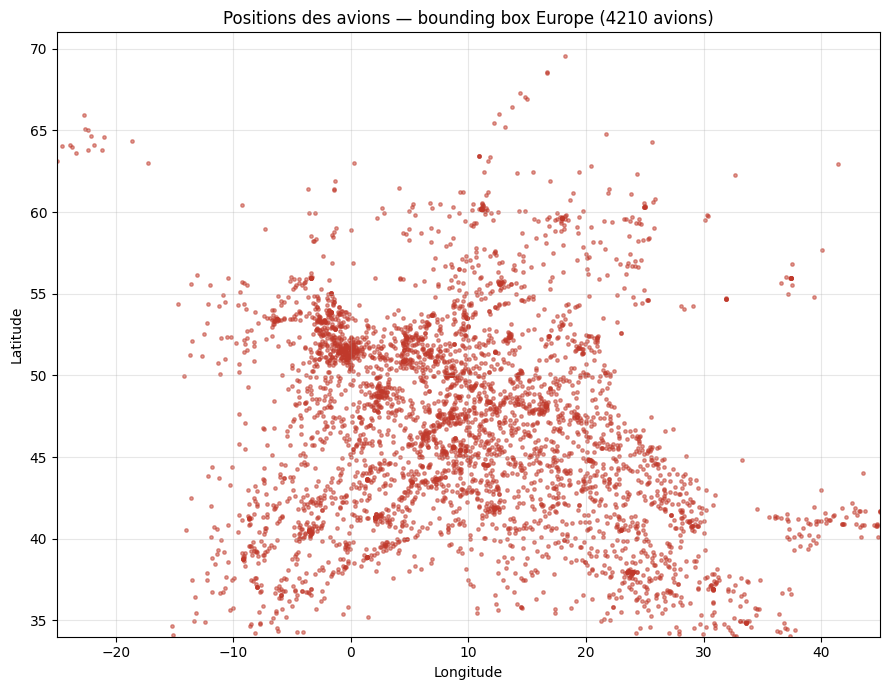

Nombre de pays d'origine distincts (origin_country) : 86

Top 10 des pays d'origine les plus représentés :
origin_country
United Kingdom    585
Germany           383
Ireland           309
Turkey            307
Malta             279
France            242
Spain             206
Poland            156
Austria           154
Switzerland       119
Name: count, dtype: int64


In [8]:
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(df_vols["longitude"], df_vols["latitude"], s=6, alpha=0.5, color="#c0392b")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(f"Positions des avions — bounding box Europe ({len(df_vols)} avions)")
ax.set_xlim(BBOX_EUROPE[1], BBOX_EUROPE[3])
ax.set_ylim(BBOX_EUROPE[0], BBOX_EUROPE[2])
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

nb_pays_distincts = df_vols["origin_country"].nunique()
print(f"Nombre de pays d'origine distincts (origin_country) : {nb_pays_distincts}")
print()
print("Top 10 des pays d'origine les plus représentés :")
print(df_vols["origin_country"].value_counts().head(10))


**Observations** : le nuage de points dessine bien les grands couloirs aériens européens (axe Londres-Paris-Francfort, arc méditerranéen), avec une densité plus forte au centre et à l'ouest de l'Europe qu'aux marges de la bounding box.

La colonne `origin_country` recense 86 pays d'origine distincts, dominés par le Royaume-Uni, l'Allemagne, l'Irlande, la Turquie et Malte (souvent lié à l'immatriculation de la compagnie plutôt qu'au pays réellement survolé).

Cette diversité confirme que la bbox européenne capture un trafic international varié — plus représentatif pour la suite du projet qu'un trafic purement domestique limité à la France.

`callsign` et `origin_country` sont les deux colonnes textuelles que j'aimerais exploiter, la seconde servant justement de clé de regroupement juste au-dessus.

Je m'assure donc qu'elles ne portent aucune trace de mauvais décodage : séquences de mojibake du type `Ã©`, `Ã¨`, `Ã `, `Ãª`, `Ã¼`, `Ã§`, `â€` (ce que devient un texte UTF-8 relu en Latin-1), caractère de remplacement U+FFFD, et plus largement présence de caractères non ASCII.

In [9]:
MOTIFS_MOJIBAKE = ("Ã©", "Ã¨", "Ã ", "Ãª", "Ã¼", "Ã§", "â€", "\ufffd")

for colonne in ("callsign", "origin_country"):
    valeurs = df_vols[colonne].dropna()
    nb_mojibake = valeurs.apply(
        lambda texte: any(motif in texte for motif in MOTIFS_MOJIBAKE)
    ).sum()
    nb_non_ascii = valeurs.apply(lambda texte: not texte.isascii()).sum()
    print(
        f"{colonne} : {nb_mojibake} valeur(s) portant un motif de mojibake, "
        f"{nb_non_ascii} valeur(s) contenant des caractères non ASCII"
    )

print()
caracteres_callsign = sorted(
    {caractere for valeur in df_vols["callsign"].dropna() for caractere in valeur}
)
print(f"Caractères rencontrés dans callsign : {caracteres_callsign}")
print()
pays_avec_diacritiques = [
    pays for pays in df_vols["origin_country"].dropna().unique() if not pays.isascii()
]
print(f"Pays d'origine contenant des diacritiques : {pays_avec_diacritiques}")
print(f"Exemples de pays d'origine : {sorted(df_vols['origin_country'].unique())[:8]}")

callsign : 0 valeur(s) portant un motif de mojibake, 0 valeur(s) contenant des caractères non ASCII
origin_country : 0 valeur(s) portant un motif de mojibake, 0 valeur(s) contenant des caractères non ASCII

Caractères rencontrés dans callsign : [' ', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']

Pays d'origine contenant des diacritiques : []
Exemples de pays d'origine : ['Algeria', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Bangladesh']


**Observations** : aucun motif de mojibake et aucun caractère non ASCII sur les deux colonnes.

Le jeu de caractères de `callsign` se limite d'ailleurs strictement à l'espace, aux dix chiffres et aux vingt-six lettres majuscules, l'espace sert de remplissage, ce qui explique les valeurs vides repérées plus haut.

Quant à `origin_country`, OpenSky renvoie des noms de pays en anglais et sans diacritique, y compris pour des pays qui en porteraient dans leur langue d'origine : la liste ne contient donc aucun caractère susceptible d'être mal décodé. Aucune réparation d'encodage n'est à prévoir sur cette source.

## 6. Quels types de données par colonne, et présence de valeurs aberrantes ?

Je vérifie les types Python réels des colonnes numériques, puis je cherche des valeurs qui sortent des bornes physiquement plausibles : altitude négative, vitesse extrême, coordonnées hors de [-90, 90] pour la latitude et [-180, 180] pour la longitude.


In [10]:
print("Types de données par colonne :")
print(df_vols.dtypes)
print()

nb_altitude_baro_negative = (df_vols["baro_altitude"] < 0).sum()
nb_altitude_geo_negative = (df_vols["geo_altitude"] < 0).sum()
nb_latitude_hors_bornes = ((df_vols["latitude"] < -90) | (df_vols["latitude"] > 90)).sum()
nb_longitude_hors_bornes = ((df_vols["longitude"] < -180) | (df_vols["longitude"] > 180)).sum()

print(f"Altitude barométrique négative : {nb_altitude_baro_negative} ligne(s)")
print(f"Altitude géométrique négative : {nb_altitude_geo_negative} ligne(s)")
print(f"Latitude hors bornes [-90, 90] : {nb_latitude_hors_bornes} ligne(s)")
print(f"Longitude hors bornes [-180, 180] : {nb_longitude_hors_bornes} ligne(s)")
print()
print("Statistiques descriptives des colonnes numériques clés :")
print(df_vols[["baro_altitude", "geo_altitude", "velocity", "vertical_rate"]].describe())
print()

ligne_vitesse_max = df_vols.loc[df_vols["velocity"].idxmax()]
print("Ligne présentant la vitesse la plus élevée (valeur suspecte à examiner) :")
print(
    ligne_vitesse_max[
        ["icao24", "callsign", "velocity", "age_position_secondes", "on_ground"]
    ]
)


Types de données par colonne :
icao24                    object
callsign                  object
origin_country            object
time_position              int64
last_contact               int64
longitude                float64
latitude                 float64
baro_altitude            float64
on_ground                   bool
velocity                 float64
true_track               float64
vertical_rate            float64
sensors                   object
geo_altitude             float64
squawk                    object
spi                         bool
position_source            int64
age_position_secondes      int64
dtype: object

Altitude barométrique négative : 11 ligne(s)
Altitude géométrique négative : 0 ligne(s)
Latitude hors bornes [-90, 90] : 0 ligne(s)
Longitude hors bornes [-180, 180] : 0 ligne(s)

Statistiques descriptives des colonnes numériques clés :
       baro_altitude  geo_altitude     velocity  vertical_rate
count    3854.000000   3772.000000  4209.000000    3831.0000

**Observations** : les types Python sont cohérents avec ce qu'on attend (numériques en `float64`/`int64`, `on_ground`/`spi` en `bool`, identifiants et texte en `object`).

Onze altitudes barométriques négatives ont été repérées sur cette capture, sur des avions à la fois au sol et en vol. La plupart restent modestes et compatibles avec un écart de calibration du capteur par rapport à la pression de référence au niveau de la mer (l'avion est alors juste après le décollage ou juste avant l'atterrissage).

Mais le minimum de la table statistique ci-dessus descend jusqu'à -304,8 mètres : un écart qui mérite d'être traité séparément plutôt que d'être plafonné à zéro comme les autres.

Plus notable encore : une vitesse de 2 012,7 m/s (environ 7 246 km/h), incompatible avec n'importe quel avion civil courant (Le Concorde allait exceptionnellement jusqu'à 2 440 km/h). Cette valeur correspond à une position vieille de 7 998 secondes (environ 2h13), ce qui confirme l'hypothèse d'une donnée périmée liée à une position "fantôme" (avion sorti de couverture radar). D'où l'idée, en Phase 2, d'une règle de nettoyage qui combine un seuil de fraîcheur et un seuil physique de vitesse maximale, plutôt qu'un filtre sur la vitesse seule.


La spécification d'OpenSky annonce des vitesses en mètres par seconde et des altitudes en mètres. Je vais confronter ces unités aux valeurs réellement observées : si les vitesses étaient en kilomètres par heure ou en nœuds, ou les altitudes en pieds, les ordres de grandeur seraient nettement différents.

In [11]:
QUANTILES = [0.01, 0.25, 0.5, 0.75, 0.99]

print("Vitesse (velocity) - quantiles observés :")
print(df_vols["velocity"].quantile(QUANTILES).round(1))
print()

ALTITUDE_CROISIERE_M = 9000
vitesse_croisiere = df_vols.loc[
    ~df_vols["on_ground"] & (df_vols["baro_altitude"] > ALTITUDE_CROISIERE_M), "velocity"
].dropna()

print(f"Avions au-dessus de {ALTITUDE_CROISIERE_M} d'altitude barométrique : {len(vitesse_croisiere)}")
print(
    f"Vitesse à ce niveau - médiane : {vitesse_croisiere.median():.1f}, "
    f"plage 1-99 % : {vitesse_croisiere.quantile(0.01):.1f} à {vitesse_croisiere.quantile(0.99):.1f}"
)
print(
    f"Médiane lue en m/s : {vitesse_croisiere.median() * 3.6:.0f} km/h "
    f"ou {vitesse_croisiere.median() * 1.94384:.0f} noeuds"
)
print()
print("Altitudes (baro_altitude / geo_altitude) - quantiles observés :")
print(df_vols[["baro_altitude", "geo_altitude"]].quantile(QUANTILES).round(0))

Vitesse (velocity) - quantiles observés :
0.01      0.0
0.25     80.6
0.50    206.6
0.75    236.0
0.99    276.2
Name: velocity, dtype: float64

Avions au-dessus de 9000 d'altitude barométrique : 2100
Vitesse à ce niveau - médiane : 234.3, plage 1-99 % : 177.9 à 280.7
Médiane lue en m/s : 843 km/h ou 455 noeuds

Altitudes (baro_altitude / geo_altitude) - quantiles observés :
      baro_altitude  geo_altitude
0.01           76.0         143.0
0.25         2450.0        2858.0
0.50         9929.0       10390.0
0.75        10980.0       11582.0
0.99        12497.0       13185.0


**Observations** : sur les 2100 avions au-dessus de 9000 d'altitude barométrique, la vitesse médiane est de 234,3 et la plage 1-99 % va de 177,9 à 280,7.

Lue en mètres par seconde, cette médiane vaut 843 km/h ou 455 nœuds, soit exactement la vitesse de croisière d'un avion de ligne. Les deux autres lectures se disqualifient d'elles-mêmes : 234 km/h correspondrait à une vitesse d'approche et non de croisière, et 234 nœuds (434 km/h) resterait très en dessous du régime attendu à cette altitude.

Les altitudes se lisent de la même façon : la médiane à 9929 et le quantile 99 % à 12 497 correspondent aux niveaux de croisière habituels exprimés en mètres, soit environ 32 600 et 41 000 pieds. Interprétées en pieds, ces mêmes valeurs placeraient la moitié de la flotte à 3000 mètres, ce qui ne correspond à aucun profil de vol de ligne.

Les unités observées confirment donc celles documentées : aucune conversion n'est à prévoir avant le stockage.

Reste un type d'anomalie que les bornes physiques ne détectent pas : le zéro qui masque une valeur inconnue. Une vitesse exactement nulle sur un avion déclaré en vol, ou une altitude exactement nulle dans la même situation, sont plus vraisemblablement des valeurs non mesurées que des mesures. Je compte ces cas et j'en regarde le détail, puis je compare `baro_altitude` et `geo_altitude` sur le même avion au même instant : ces deux mesures d'altitude ne devraient pas s'écarter de plus de quelques centaines de mètres.

In [12]:
en_vol = df_vols.loc[~df_vols["on_ground"]]

print(f"Avions en vol (on_ground == False) : {len(en_vol)}")
print(f"velocity == 0 en vol : {(en_vol['velocity'] == 0).sum()}")
print(f"geo_altitude == 0 en vol : {(en_vol['geo_altitude'] == 0).sum()}")
print(f"baro_altitude == 0 en vol : {(en_vol['baro_altitude'] == 0).sum()}")
print()
print(
    en_vol.loc[
        en_vol["velocity"] == 0,
        ["icao24", "callsign", "velocity", "baro_altitude", "geo_altitude", "age_position_secondes"],
    ]
)
print()

ecart_altitudes = (df_vols["baro_altitude"] - df_vols["geo_altitude"]).abs()
SEUIL_ECART_ALTITUDES_M = 1000
masque_ecart_anormal = ecart_altitudes > SEUIL_ECART_ALTITUDES_M

print(
    f"Écart |baro_altitude - geo_altitude| - médiane : {ecart_altitudes.median():.1f} m, "
    f"quantile 99 % : {ecart_altitudes.quantile(0.99):.1f} m, max : {ecart_altitudes.max():.1f} m"
)
print(f"Écarts supérieurs à {SEUIL_ECART_ALTITUDES_M} m : {int(masque_ecart_anormal.sum())} ligne(s)")
print(
    df_vols.loc[
        masque_ecart_anormal,
        ["icao24", "callsign", "on_ground", "baro_altitude", "geo_altitude", "age_position_secondes"],
    ]
)

Avions en vol (on_ground == False) : 3835
velocity == 0 en vol : 7
geo_altitude == 0 en vol : 0
baro_altitude == 0 en vol : 2

      icao24  callsign  velocity  baro_altitude  geo_altitude  \
855   4910ed  RTV2M          0.0         182.88        281.94   
1771  4b4391  HBZPH          0.0         632.46        685.80   
2075  3d1e3c  DEJRW          0.0         449.58        510.54   
3098  30083d  ICFAM          0.0           7.62         60.96   
3599  4d22b9  RYR674         0.0        4107.18           NaN   
3921  4b19ef  SWR7PZ         0.0         411.48           NaN   
4000  486a30  LIFELN4        0.0           7.62         60.96   

      age_position_secondes  
855                       0  
1771                      1  
2075                      0  
3098                      0  
3599                      8  
3921                    180  
4000                     22  

Écart |baro_altitude - geo_altitude| - médiane : 327.7 m, quantile 99 % : 787.1 m, max : 11978.6 m
Écarts supér

**Observations** : sur les 3835 avions déclarés en vol, 7 affichent une vitesse exactement nulle et 2 une altitude barométrique exactement nulle ; aucune altitude géométrique n'est à zéro.

C'est rassurant : les sept vitesses nulles concernent des avions très bas (de 7,62 à 4107,18 mètres) sur des positions "fraîches" (au plus 180 secondes), donc vraisemblablement des appareils en attente ou en tout début de roulage dont `on_ground` n'a pas encore basculé, plutôt que des mesures perdues. Le zéro reste malgré tout ambigu sur ces colonnes : au moment du nettoyage, il devra être traité comme une valeur non renseignée et non comme une vitesse ou une altitude réelle.

La comparaison des deux altitudes donne un écart médian de 327,7 mètres, sous 787,1 mètres pour 99 % des avions : c'est l'ordre de grandeur attendu entre une altitude-pression et une altitude GPS.

Neuf lignes sortent de cet intervalle, jusqu'à 11 978,6 mètres d'écart. Sept d'entre elles portent une position ancienne (de 603 à 14 897 secondes) : les deux mesures ne datent alors plus du même instant, ce qui suffit à expliquer l'incohérence, et le filtre sur l'âge de la position retenu plus loin les écarte au passage.

Les deux dernières ont une position fraîche (0 et 68 secondes) et relèvent d'une vraie erreur de mesure : `MNE325` annonce 12 496,80 mètres au barométrique contre 518,16 au géométrique, ce qu'aucune situation de vol ne peut produire. Un contrôle de cohérence entre les deux altitudes sera donc à garder dans le pipeline, en plus du filtre sur la fraîcheur.

## 7. Quel volume de données cela représente-t-il ?

Je calcule la taille du fichier JSON de cette capture, puis je projette le volume total sur la durée du projet selon différentes fréquences de collecte.


In [13]:
taille_octets = os.path.getsize(chemin_fichier)
taille_ko = taille_octets / 1024
taille_mo = taille_ko / 1024

print(f"Nombre de lignes de cette capture : {len(df_vols)}")
print(f"Taille du fichier JSON brut : {taille_octets} octets ({taille_ko:.1f} Ko / {taille_mo:.3f} Mo)")
print()

# Volume total si on répète cette collecte sur deux semaines
DUREE_COLLECTE_JOURS = 14
print("Projection sur deux semaines de collecte, selon la fréquence choisie :")
for frequence_minutes in (5, 10, 15):
    nb_captures = DUREE_COLLECTE_JOURS * 24 * 60 / frequence_minutes
    volume_total_mo = nb_captures * taille_mo
    volume_total_go = volume_total_mo / 1024
    print(
        f"  - toutes les {frequence_minutes:>2} min -> {nb_captures:.0f} captures, "
        f"volume total estimé : {volume_total_mo:.0f} Mo (~{volume_total_go:.2f} Go)"
    )


Nombre de lignes de cette capture : 4210
Taille du fichier JSON brut : 1167170 octets (1139.8 Ko / 1.113 Mo)

Projection sur deux semaines de collecte, selon la fréquence choisie :
  - toutes les  5 min -> 4032 captures, volume total estimé : 4488 Mo (~4.38 Go)
  - toutes les 10 min -> 2016 captures, volume total estimé : 2244 Mo (~2.19 Go)
  - toutes les 15 min -> 1344 captures, volume total estimé : 1496 Mo (~1.46 Go)


**Observations** : une capture représente environ 1 Mo de JSON brut pour près de 4 000 avions sur l'Europe. Sur deux semaines, une collecte toutes les 5 minutes représenterait environ 4 Go de données brutes, contre environ 1,4 Go pour une collecte toutes les 15 minutes. C'est un volume tout à fait gérable sur disque local ou dans PostgreSQL une fois structuré (Phase 2), mais cela montre bien qu'un stockage JSON brut non compressé sur toute la durée du projet finit par peser plusieurs giga-octets.

Une fréquence de 10 à 15 minutes semble être un bon compromis entre fraîcheur et volumétrie : l'essentiel des vols commerciaux dure largement plus de 15 minutes, donc collecter toutes les 5 minutes n'apporterait pas grand-chose de plus.

## 8. Rapport de profiling automatisé (ydata-profiling)

L'exploration ci-dessus répond à des questions précises, choisies parce qu'elles débouchent sur des décisions concrètes pour le pipeline. Elle reste forcément partielle : elle ne couvre pas systématiquement toutes les colonnes ni toutes les corrélations possibles. Le rapport `ydata-profiling` généré ci-dessous complète cette exploration ciblée par une vue exhaustive, utile pour vérifier que rien d'important n'a été manqué.


In [14]:
from ydata_profiling import ProfileReport

DOSSIER_PROFILING = os.path.join(RACINE_PROJET, "data", "profiling_reports")
os.makedirs(DOSSIER_PROFILING, exist_ok=True)
chemin_rapport = os.path.join(DOSSIER_PROFILING, "opensky_profiling_report.html")

warnings.filterwarnings("ignore", category=FutureWarning, module="ydata_profiling")

rapport = ProfileReport(
    df_vols,
    title="Rapport de profiling - OpenSky Network",
    explorative=True,
    progress_bar=False,
)
rapport.to_file(chemin_rapport)

print(f"Rapport de profiling généré : {chemin_relatif_projet(chemin_rapport)}")


## 9. Synthèse et conclusions

**Complétude générale** : sur cette capture, `sensors` est vide à 100 % et n'apporte rien dans notre cas d'usage (requête par bounding box, sans authentification par capteur) — à supprimer dès le nettoyage. `squawk`, `geo_altitude`, `baro_altitude` et `vertical_rate` sont complets entre 83 % et 92 %, mais cette non-complétude est structurelle (liée au statut sol/vol de l'avion), pas aléatoire — à traiter par une logique conditionnelle plutôt qu'une imputation générique. `velocity` est par ailleurs complet à plus de 99,9 % mais pas toujours à 100 % (une valeur manquante isolée observée sur cette capture) : un point mineur à surveiller plutôt qu'une non-complétude structurelle.

**Anomalies repérées** :
- Des altitudes barométriques négatives : la plupart restent très légèrement négatives, à plafonner à zéro plutôt qu'à exclure, mais le minimum observé sur cette capture descend jusqu'à -304,8 mètres — un écart bien plus extrême, qui mérite un traitement séparé plutôt qu'un simple plafonnement.
- Une vitesse extrême (environ 2 013 m/s) associée à une position vieille de plus de 2h — un filtre combinant fraîcheur et plausibilité physique sera nécessaire avant d'utiliser cette donnée comme feature.
- Aucune coordonnée hors des bornes géographiques valides.
- Environ 1,6 % des positions ont plus de 5 minutes d'ancienneté, identifiables via `age_position_secondes`, à recalculer de la même façon dans le pipeline de nettoyage (Phase 2).

**Pour la suite (Phase 2)** :
1. Supprimer la colonne `sensors` (aucune valeur informative).
2. Ajouter une règle de nettoyage sur `baro_altitude`/`geo_altitude` (plancher à zéro) et sur `velocity` combinée à l'âge de la position (rejet des valeurs implausibles sur des positions périmées).
3. Garder `on_ground` comme variable de segmentation avant de traiter les champs d'altitude, plutôt que de les traiter tous de la même façon.
4. Retenir une fréquence de collecte de 10 à 15 minutes pour équilibrer fraîcheur et volumétrie.
5. Nettoyer les espaces du champ `callsign` (`strip()`) avant toute jointure avec les autres sources — une partie des valeurs ne contient que des espaces une fois nettoyées.

Ces constats seront repris dans le chapitre "Data Profiling" du Rendu 1 (`docs/rendu1_decouverte_exploration.md`).


## 10. Nettoyage appliqué sur cette capture

Les règles ci-dessus ont été identifiées au fil de cette exploration, mais restent pour l'instant seulement notées. J'applique maintenant concrètement les deux plus directes sur `df_vols` : la suppression de la colonne `sensors`, vide à 100 %, et un filtre combinant l'âge de la position (`age_position_secondes`, déjà calculé plus haut, seuil de 300 secondes) et une vitesse maximale physiquement plausible, pour écarter les positions périmées comme celle à 2012,7 m/s repérée plus tôt. Le traitement différencié de `baro_altitude`/`geo_altitude` selon le statut `on_ground`, qui suppose une logique conditionnelle plus élaborée, reste réservé au script de nettoyage générique de la Phase 2, une fois les trois sources fusionnées.

In [15]:
nb_lignes_avant, nb_colonnes_avant = df_vols.shape

df_vols_nettoye = df_vols.drop(columns=["sensors"])

SEUIL_VITESSE_PLAUSIBLE_MS = 400
masque_vitesse_implausible = (
    (df_vols_nettoye["age_position_secondes"] > seuil_secondes)
    & (df_vols_nettoye["velocity"] > SEUIL_VITESSE_PLAUSIBLE_MS)
)
nb_lignes_supprimees = int(masque_vitesse_implausible.sum())
df_vols_nettoye = df_vols_nettoye.loc[~masque_vitesse_implausible].reset_index(drop=True)

nb_lignes_apres, nb_colonnes_apres = df_vols_nettoye.shape

print(f"Avant nettoyage : {nb_lignes_avant} lignes, {nb_colonnes_avant} colonnes")
print(f"Après nettoyage : {nb_lignes_apres} lignes, {nb_colonnes_apres} colonnes")
print(
    f"Lignes supprimées (vitesse > {SEUIL_VITESSE_PLAUSIBLE_MS} m/s sur une position "
    f"vieille de plus de {seuil_secondes} s) : {nb_lignes_supprimees}"
)

Avant nettoyage : 4210 lignes, 18 colonnes
Après nettoyage : 4205 lignes, 17 colonnes
Lignes supprimées (vitesse > 400 m/s sur une position vieille de plus de 300 s) : 5


**Observations** : sur cette capture, `df_vols_nettoye` passe de 4210 à 4205 lignes et de 18 à 17 colonnes une fois ces deux règles appliquées (chiffres qui varieront légèrement à chaque nouvelle exécution du notebook, cette capture n'étant pas figée).

Retirer `sensors` ne fait perdre aucune information puisqu'elle n'en contenait aucune : c'est une colonne en moins à porter jusqu'au schéma en étoile. Le filtre combiné âge/vitesse, lui, retire 5 lignes correspondant à des positions à la fois périmées (plus de 5 minutes) et affichant une vitesse au-delà de 400 m/s, une borne fixée nettement au-dessus de la vitesse de croisière de n'importe quel avion suivi ici (et au-delà de la vitesse du son au niveau de la mer), donc sans risque d'écarter une vitesse réelle.

Le traitement conditionnel de `baro_altitude`/`geo_altitude` selon `on_ground` reste prévu pour la Phase 2 : il touche aux deux autres sources en même temps (schéma de fusion), contrairement aux deux règles appliquées ici qui ne concernent qu'OpenSky.